# Milestone 5 — the final 11-class model

The brief: retrain my best architecture with **11 outputs**, on the **same split**. Only the labels and the last layer change.

- Architecture: **ViT-B/16, last 2 encoder blocks + a new head fine-tuned** (the Milestone 4 winner), same recipe:
  6 epochs, lr 1e-4, flips, class weights, best epoch kept on validation.
- Labels: `training_gt.csv`, one per lesion, columns in the order that the submission uses.
- The model and its validation transform live in `m5_final/pipeline.py`, so `predict.py` and
  `make_submission.py` use **exactly** the same code as this notebook.

In Colab: Runtime → Change runtime type → T4 GPU, then Runtime → Run all (about 10 minutes).

## 0. Setup

In [1]:
# PURPOSE: get my repo and the dataset into Colab (skip this cell on my laptop).

import os, urllib.request, zipfile
from pathlib import Path

!git clone -q https://github.com/sopipi180/ComputerVisionandSpeechRecognition.git
%cd ComputerVisionandSpeechRecognition

DEST = Path("/content/milk10k")
if not (DEST / "metadata.csv").exists():
    urllib.request.urlretrieve(
        "https://isic-archive.s3.amazonaws.com/dois/10.34970-648456/milk10k.zip",
        "/content/milk10k.zip")
    with zipfile.ZipFile("/content/milk10k.zip") as z:
        z.extractall(DEST)

os.environ["MILK10K_DIR"] = str(DEST)            # common/config.py reads this

/content/ComputerVisionandSpeechRecognition


In [2]:
# PURPOSE: libraries, my repo, and CPU or GPU.

import sys, copy, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "common" / "config.py").is_file())
sys.path.insert(0, str(ROOT))
from common import config
from m5_final.pipeline import CLASSES, MODEL_PATH, load_image, prep, build_model   # the shared final pipeline

OUT = ROOT / "m5_final"
CACHE = OUT / "_cache"                                # decoded images (not in git)
CACHE.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(config.SEED)
print(device, CLASSES)

cuda ['AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


## 1. Data — same split, 11-class labels

Same lesion-level split and the same dermoscopic photo per lesion as Milestones 2–4.
The 11-class label comes from `training_gt.csv` (one-hot, one row per lesion): the column with the 1 is the class.

In [3]:
# PURPOSE: MY split + the 11-class label of every lesion, read from training_gt.csv (as in the brief).

gt = pd.read_csv(config.GT_PATH)
assert list(gt.columns[1:]) == CLASSES, "training_gt.csv column order must be the submission order"
gt["label11"] = gt[CLASSES].values.argmax(1)                         # 0..10

splits, y = {}, {}
for name in ["train", "val", "test"]:
    df = pd.read_csv(config.SPLIT_DIR / f"{name}.csv")
    df = df[df["image_type"].str.startswith("derm")].reset_index(drop=True)
    df = df.merge(gt[["lesion_id", "label11"]], on="lesion_id", how="left", validate="one_to_one")
    assert (df["label11"].map(lambda i: CLASSES[i]) == df["dx11"]).all()   # agrees with my Milestone 1 labels
    splits[name] = df
    y[name] = torch.tensor(df["label11"].to_numpy())

pd.DataFrame({name: df["dx11"].value_counts().reindex(CLASSES).fillna(0).astype(int)
              for name, df in splits.items()})

,train,val,test
dx11,,,
AKIEC,218,41,44
BCC,1744,377,401
BEN_OTH,27,11,6
BKL,385,82,77
DF,37,8,7
INF,32,12,6
MAL_OTH,7,2,0
MEL,322,65,63
NV,534,110,102


Very unbalanced: BCC has 1,744 training lesions, MAL_OTH has 7 (and **none** in test).
As in Milestone 1 (B3), I keep all 11 classes and use class weights rather than merging the rare ones.

**Metric**: macro-F1 over the classes that appear in that split (MAL_OTH is absent from test, so it can't be scored there).

In [4]:
# PURPOSE: decode every image once with the pipeline's load_image (the validation transform, step 1).

def load_images(df, name):
    f = CACHE / f"images_{name}.pt"
    if not f.exists():
        torch.save(torch.stack([load_image(config.image_path(i)) for i in df["isic_id"]]), f)
    return torch.load(f)

X = {name: load_images(df, name) for name, df in splits.items()}
print({name: tuple(x.shape) for name, x in X.items()})

{'train': (3667, 3, 224, 224), 'val': (786, 3, 224, 224), 'test': (787, 3, 224, 224)}


## 2. Train: ViT-B/16, last 2 blocks + new 11-class head

In [5]:
# PURPOSE: the Milestone 4 training code, unchanged except for 11 classes.

def augment(xb):
    n = xb.size(0)
    flip_h = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5
    xb = torch.where(flip_h, xb.flip(3), xb)                              # left-right
    flip_v = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5
    return torch.where(flip_v, xb.flip(2), xb)                            # up-down

def macro_f1(y_true, y_pred):
    """Macro-F1 over the classes present in y_true (a class with no lesions can't be scored)."""
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro")

@torch.no_grad()
def predict_proba(model, X, batch_size=128):
    model.eval()
    return torch.cat([model(prep(X[i:i + batch_size].to(device))).softmax(1).cpu()
                      for i in range(0, len(X), batch_size)])

counts = torch.bincount(y["train"], minlength=len(CLASSES)).float()
class_weights = (len(y["train"]) / (len(CLASSES) * counts)).to(device)    # rare classes count more
print(dict(zip(CLASSES, class_weights.cpu().numpy().round(2))))

def fit(model, params, epochs, lr, batch_size=64):
    model.to(device)
    optimizer = torch.optim.Adam(params, lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    best = {"f1": -1}
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X["train"]))
        for i in range(0, len(X["train"]), batch_size):
            idx = order[i:i + batch_size]
            xb, yb = augment(prep(X["train"][idx].to(device))), y["train"][idx].to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
        f1 = macro_f1(y["val"], predict_proba(model, X["val"]).argmax(1))
        print(f"epoch {epoch} val macro-F1 {f1:.3f}")
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])                                  # early stopping: keep the best epoch
    return best

{'AKIEC': np.float32(1.53), 'BCC': np.float32(0.19), 'BEN_OTH': np.float32(12.35), 'BKL': np.float32(0.87), 'DF': np.float32(9.01), 'INF': np.float32(10.42), 'MAL_OTH': np.float32(47.62), 'MEL': np.float32(1.04), 'NV': np.float32(0.62), 'SCCKA': np.float32(1.03), 'VASC': np.float32(9.26)}


In [6]:
# PURPOSE: build the final model from the pipeline and fine-tune the same layers as in Milestone 4.

torch.manual_seed(0)
model = build_model(pretrained=True)                                      # ViT-B/16, ImageNet weights, 11-class head
for name, p in model.named_parameters():
    p.requires_grad = name.startswith(("encoder.layers.encoder_layer_10", "encoder.layers.encoder_layer_11",
                                       "encoder.ln", "heads"))

trainable = [p for p in model.parameters() if p.requires_grad]
print(f"training {sum(p.numel() for p in trainable):,} of {sum(p.numel() for p in model.parameters()):,} weights")
best = fit(model, trainable, epochs=6, lr=1e-4)
print(f"best epoch {best['epoch']}, validation macro-F1 {best['f1']:.3f}")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 148MB/s]


training 14,185,739 of 85,807,115 weights
epoch 0 val macro-F1 0.275
epoch 1 val macro-F1 0.332
epoch 2 val macro-F1 0.332
epoch 3 val macro-F1 0.329
epoch 4 val macro-F1 0.373
epoch 5 val macro-F1 0.344
best epoch 4, validation macro-F1 0.373


## 3. Test — opened once

Nothing is chosen after this point.

In [7]:
# PURPOSE: score the final model on the test split, once.

proba = {name: predict_proba(model, X[name]) for name in ["val", "test"]}
pred = {name: p.argmax(1) for name, p in proba.items()}
scores = {name: macro_f1(y[name], pred[name]) for name in pred}
print(f"macro-F1  validation {scores['val']:.3f} | test {scores['test']:.3f}")

present = np.unique(y["test"])
report = classification_report(y["test"], pred["test"], labels=present,
                               target_names=[CLASSES[i] for i in present], digits=3, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.round(3)
per_class.to_csv(OUT / "test_per_class.csv")
per_class

macro-F1  validation 0.373 | test 0.405


,precision,recall,f1-score,support
AKIEC,0.256,0.455,0.328,44.0
BCC,0.855,0.763,0.806,401.0
BEN_OTH,0.032,0.167,0.054,6.0
BKL,0.444,0.104,0.168,77.0
DF,0.211,0.571,0.308,7.0
INF,0.000,0.000,0.000,6.0
MEL,0.476,0.476,0.476,63.0
NV,0.716,0.765,0.739,102.0
SCCKA,0.511,0.658,0.575,73.0
VASC,0.500,0.750,0.600,8.0


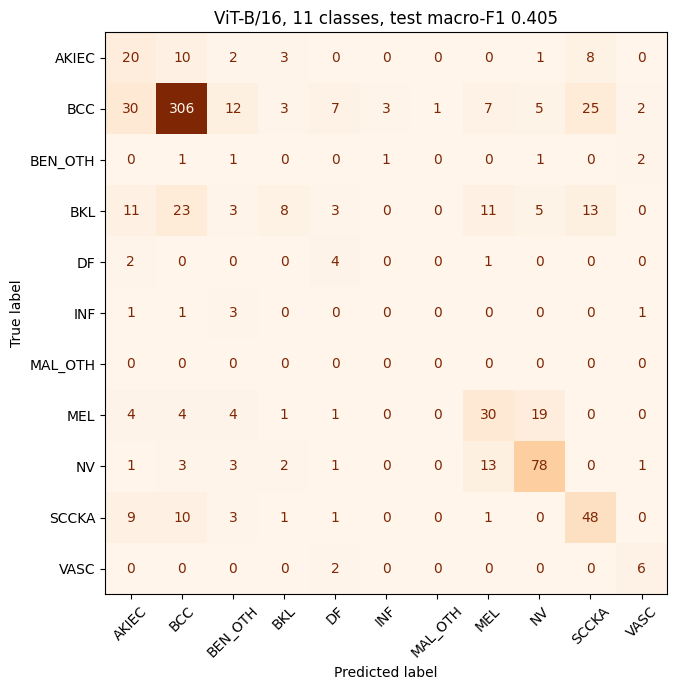

In [8]:
# PURPOSE: where the 11-class mistakes go. Rows: true class; columns: predicted.

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y["test"], pred["test"], labels=range(len(CLASSES)),
                                        display_labels=CLASSES, cmap="Oranges", ax=ax, colorbar=False)
ax.set_title(f"ViT-B/16, 11 classes, test macro-F1 {scores['test']:.3f}")
plt.xticks(rotation=45)
plt.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
fig.savefig(OUT / "figures" / "m5_test_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# PURPOSE: the numbers for the model card, saved in one file.

results = {"model": "ViT-B/16, last 2 blocks + head fine-tuned, 11 classes",
           "best_epoch": best["epoch"], "val_macro_f1": round(scores["val"], 3), "test_macro_f1": round(scores["test"], 3),
           "test_accuracy": round(float((pred["test"] == y["test"]).float().mean()), 3),
           "majority_test_macro_f1": round(macro_f1(y["test"], torch.full_like(y["test"], CLASSES.index("BCC"))), 3),
           "n_train": len(y["train"]), "n_val": len(y["val"]), "n_test": len(y["test"])}
(OUT / "results.json").write_text(json.dumps(results, indent=2))
results

{'model': 'ViT-B/16, last 2 blocks + head fine-tuned, 11 classes',
 'best_epoch': 4,
 'val_macro_f1': 0.373,
 'test_macro_f1': 0.405,
 'test_accuracy': 0.637,
 'majority_test_macro_f1': 0.068,
 'n_train': 3667,
 'n_val': 786,
 'n_test': 787}

## 4. Save, and check that `predict.py` gives the same answer

`predict(image_path)` re-opens the image file and applies the pipeline's transform from scratch.
If it gives the same probabilities as this notebook, the deliverable really uses the validation transform.

In [14]:
!git pull -q

In [15]:
# PURPOSE: save the weights where predict.py looks for them, then compare predict() with the notebook.

torch.save(model.state_dict(), MODEL_PATH)

from m5_final.predict import predict
for i in range(3):
    path = config.image_path(splits["test"]["isic_id"][i])
    p_script = np.array(list(predict(path).values()))
    p_notebook = proba["test"][i].numpy()
    print(path.name, "max difference:", float(np.abs(p_script - p_notebook).max()))

ISIC_0080219.jpg max difference: 8.940696716308594e-07
ISIC_0097302.jpg max difference: 1.430511474609375e-06
ISIC_0116442.jpg max difference: 1.1920928955078125e-06


## 5. The leaderboard's metric, and one threshold per class

The official score binarises every probability at **0.5**, then averages the F1 of the 11 classes.
With softmax outputs a rare class seldom reaches 0.5, so the argmax macro-F1 above **overestimates** the official score.
`tune_thresholds.py` scores my split the official way, tunes one threshold per class on **validation**,
reports test with them, and saves `thresholds.json` for `make_submission.py`.

In [16]:
# PURPOSE: honest local estimate of the official score, and per-class thresholds tuned on validation.

!python m5_final/tune_thresholds.py
pd.read_csv(OUT / "local_scores.csv")

  val: 786/786
  test: 787/787
     split  argmax macro-F1  official-style (0.5)  official-style, tuned thresholds
validation            0.373                 0.371                             0.435
      test            0.405                 0.387                             0.428

thresholds: {'AKIEC': 0.5, 'BCC': 0.2, 'BEN_OTH': 0.5, 'BKL': 0.2, 'DF': 0.55, 'INF': 0.25, 'MAL_OTH': 0.5, 'MEL': 0.2, 'NV': 0.25, 'SCCKA': 0.6, 'VASC': 0.5}
test F1 per class, tuned: {'AKIEC': np.float64(0.297), 'BCC': np.float64(0.825), 'BEN_OTH': np.float64(0.091), 'BKL': np.float64(0.318), 'DF': np.float64(0.4), 'INF': np.float64(0.0), 'MEL': np.float64(0.495), 'NV': np.float64(0.735), 'SCCKA': np.float64(0.517), 'VASC': np.float64(0.6)}

wrote /content/ComputerVisionandSpeechRecognition/m5_final/thresholds.json and /content/ComputerVisionandSpeechRecognition/m5_final/local_scores.csv
Note: validation was used to tune, so its tuned score is optimistic; quote the TEST one.


,split,argmax macro-F1,official-style (0.5),"official-style, tuned thresholds"
0,validation,0.373,0.371,0.435
1,test,0.405,0.387,0.428


In [17]:
# PURPOSE: run the leaderboard script exactly as anyone would (here on my own test split, as a check; the official file is made on my laptop).

!python m5_final/make_submission.py
pd.read_csv(OUT / "submission.csv").head()

787 lesions (1574 rows) from test.csv, on cuda
  787/787
applied thresholds.json: {'AKIEC': 0.5, 'BCC': 0.2, 'BEN_OTH': 0.5, 'BKL': 0.2, 'DF': 0.55, 'INF': 0.25, 'MAL_OTH': 0.5, 'MEL': 0.2, 'NV': 0.25, 'SCCKA': 0.6, 'VASC': 0.5}
checks passed - wrote /content/ComputerVisionandSpeechRecognition/m5_final/submission.csv (787 rows x 12 columns)


,lesion,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_5310300,0.006362,0.003785,0.036741,0.053593,0.001492,0.001115,0.001571,0.256184,0.884704,0.000129,0.000492
1,IL_4099426,0.133308,0.802214,0.000360,0.156201,0.007129,0.004058,0.000219,0.003731,0.003635,0.087390,0.002041
2,IL_8703940,0.202369,0.557025,0.004299,0.137541,0.001045,0.004496,0.000190,0.005204,0.011763,0.361466,0.001766
3,IL_7085786,0.073044,0.547865,0.000966,0.123741,0.000129,0.000869,0.000780,0.025085,0.012154,0.483734,0.001962
4,IL_1843945,0.020052,0.192364,0.834710,0.034933,0.007738,0.007751,0.014608,0.030294,0.011061,0.007275,0.000946


In [18]:
# Colab only: download the files, then put them in m5_final/ on my laptop (the figure in m5_final/figures/).
from google.colab import files
for f in ["model_m5.pt", "results.json", "test_per_class.csv", "thresholds.json", "local_scores.csv", "figures/m5_test_confusion.png"]:
    files.download(str(OUT / f))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>